In [1]:
import os
import pandas as pd

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("anandshaw2001/video-game-sales")

print("Path to dataset files:", path)

100%|██████████| 381k/381k [00:00<00:00, 37.6MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/anandshaw2001/video-game-sales/versions/1


In [3]:
print(os.listdir(path))

['vgsales.csv']


In [4]:
df = pd.read_csv(f"{path}/vgsales.csv")

In [27]:
df

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...,...
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16594,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16596,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


In [5]:
df.sample(5)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
8167,8169,Otomedius Excellent,X360,NaN,Shooter,Unknown,0.13,0.00,0.04,0.01,0.18
185,186,FIFA Soccer 13,X360,2012.0,Action,Electronic Arts,1.08,3.48,0.03,0.58,5.18
12350,12352,Pro Yaky? Spirits 2013,PSV,2013.0,Sports,Konami Digital Entertainment,0.00,0.00,0.06,0.00,0.06
5510,5512,Hatsune Miku: Project Diva Extend,PSP,2011.0,Misc,Sega,0.00,0.00,0.33,0.00,0.33
755,757,The Sims: House Party,PC,2001.0,Simulation,Electronic Arts,1.23,0.83,0.00,0.10,2.16


In [6]:
df.shape

(16598, 11)

In [7]:
df.isnull().sum()

,0
Rank,0
Name,0
Platform,0
Year,271
Genre,0
Publisher,58
NA_Sales,0
EU_Sales,0
JP_Sales,0
Other_Sales,0


In [8]:
df[df['Publisher'].isnull()]

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
470,471,wwe Smackdown vs. Raw 2006,PS2,NaN,Fighting,NaN,1.57,1.02,0.00,0.41,3.00
1303,1305,Triple Play 99,PS,NaN,Sports,NaN,0.81,0.55,0.00,0.10,1.46
1662,1664,Shrek / Shrek 2 2-in-1 Gameboy Advance Video,GBA,2007.0,Misc,NaN,0.87,0.32,0.00,0.02,1.21
2222,2224,Bentley's Hackpack,GBA,2005.0,Misc,NaN,0.67,0.25,0.00,0.02,0.93
3159,3161,Nicktoons Collection: Game Boy Advance Video V...,GBA,2004.0,Misc,NaN,0.46,0.17,0.00,0.01,0.64
3166,3168,SpongeBob SquarePants: Game Boy Advance Video ...,GBA,2004.0,Misc,NaN,0.46,0.17,0.00,0.01,0.64
3766,3768,SpongeBob SquarePants: Game Boy Advance Video ...,GBA,2004.0,Misc,NaN,0.38,0.14,0.00,0.01,0.53
4145,4147,Sonic the Hedgehog,PS3,NaN,Platform,NaN,0.00,0.48,0.00,0.00,0.48
4526,4528,The Fairly Odd Parents: Game Boy Advance Video...,GBA,2004.0,Misc,NaN,0.31,0.11,0.00,0.01,0.43
4635,4637,The Fairly Odd Parents: Game Boy Advance Video...,GBA,2004.0,Misc,NaN,0.30,0.11,0.00,0.01,0.42


In [9]:
df["Publisher"][df["Publisher"].isnull()].unique()

array([nan], dtype=object)

In [10]:
df.loc[df['Name'] == 'wwe Smackdown vs. Raw 2006', "Publisher"] = 'THQ'
df.loc[df['Name'] == 'Triple Play 99', "Publisher"] = 'EA Sport'
df.loc[df['Name'] == 'Shrek / Shrek 2 2-in-1 Gameboy Advance Video', "Publisher"] = 'Majesco Games'
df.loc[df['Name'] == "Bentley's Hackpack", "Publisher"] = 'Sony Computer Entertainment'
df.loc[df['Name'] == "Nicktoons Collection: Game Boy Advance Video V...", "Publisher"] = 'Majesco'

In [11]:
df['Publisher'] = df['Publisher'].fillna('unknown')

In [12]:
df[df['Publisher'].isnull()]

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales


data yang missing tadi ada beberpa sudah saya isi manual akan tetapi mengingat nilai yang missing itu ada 50 an baris maka saya memutuskan untuk tidak memasukkan semua, untuk mempersingkat waktu jadi saya isi dengan (unknown).
kenapa? karena jumlah misssing hanya sedikit 58 baris dikurang 5 jadi 53 baris Nan maka menurut saya tidak akan mempengaruhi isi dari keseluruhan dataset, yang dimana dataset ini memiliki 16598 baris dan 11 kolom.

karena mengingat yang menjadi fokus utama saya adalah melihat tren tahunan dari penjualan game maka part itu saya skip.
dan fokus untuk melihat tren penjualan, pada kolom year juga masih banyak yang harus di rapikan, mengingat ada 271 baris Nan

In [13]:
df[df['Year'].isnull()]

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
179,180,Madden NFL 2004,PS2,NaN,Sports,Electronic Arts,4.26,0.26,0.01,0.71,5.23
377,378,FIFA Soccer 2004,PS2,NaN,Sports,Electronic Arts,0.59,2.36,0.04,0.51,3.49
431,432,LEGO Batman: The Videogame,Wii,NaN,Action,Warner Bros. Interactive Entertainment,1.86,1.02,0.00,0.29,3.17
470,471,wwe Smackdown vs. Raw 2006,PS2,NaN,Fighting,THQ,1.57,1.02,0.00,0.41,3.00
607,608,Space Invaders,2600,NaN,Shooter,Atari,2.36,0.14,0.00,0.03,2.53
...,...,...,...,...,...,...,...,...,...,...,...
16307,16310,Freaky Flyers,GC,NaN,Racing,Unknown,0.01,0.00,0.00,0.00,0.01
16327,16330,Inversion,PC,NaN,Shooter,Namco Bandai Games,0.01,0.00,0.00,0.00,0.01
16366,16369,Hakuouki: Shinsengumi Kitan,PS3,NaN,Adventure,Unknown,0.01,0.00,0.00,0.00,0.01
16427,16430,Virtua Quest,GC,NaN,Role-Playing,Unknown,0.01,0.00,0.00,0.00,0.01


In [14]:
df_year = df.dropna(subset=['Year']).copy()
df_year['Year'] = df_year['Year'].astype(int)

In [15]:
yearly = df_year.groupby('Year')['Global_Sales'].sum()
print(yearly)

Year
1980     11.38
1981     35.77
1982     28.86
1983     16.79
1984     50.36
1985     53.94
1986     37.07
1987     21.74
1988     47.22
1989     73.45
1990     49.39
1991     32.23
1992     76.16
1993     45.98
1994     79.17
1995     88.11
1996    199.15
1997    200.98
1998    256.47
1999    251.27
2000    201.56
2001    331.47
2002    395.52
2003    357.85
2004    419.31
2005    459.94
2006    521.04
2007    611.13
2008    678.90
2009    667.30
2010    600.45
2011    515.99
2012    363.54
2013    368.11
2014    337.05
2015    264.44
2016     70.93
2017      0.05
2020      0.29
Name: Global_Sales, dtype: float64


In [16]:
yearly = df_year.groupby('Year')['Global_Sales'].sum()
yearly

,Global_Sales
Year,
1980,11.38
1981,35.77
1982,28.86
1983,16.79
1984,50.36
1985,53.94
1986,37.07
1987,21.74
1988,47.22


In [17]:
print(yearly.idxmax(), yearly.max())   # tahun dan nilai tertinggi
print(yearly.nlargest(5))              # 5 tahun terbaik

2008 678.9
Year
2008    678.90
2009    667.30
2007    611.13
2010    600.45
2006    521.04
Name: Global_Sales, dtype: float64


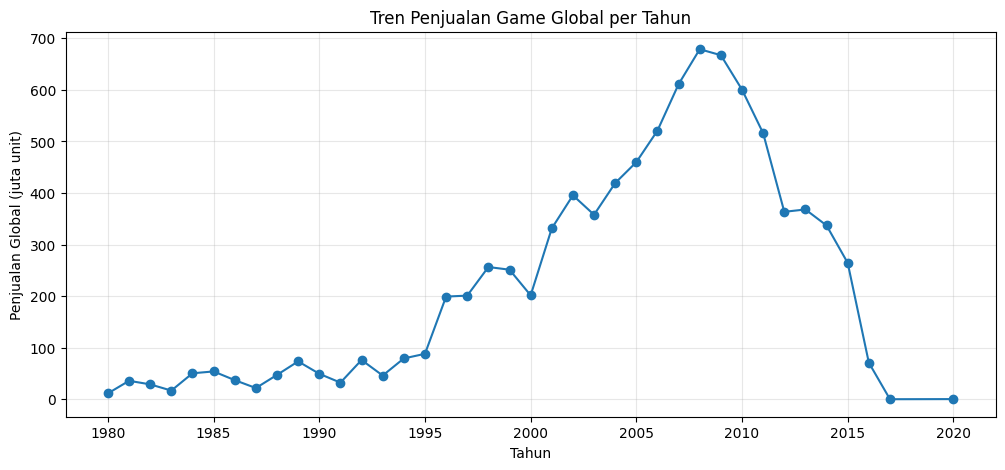

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.plot(yearly.index, yearly.values, marker='o')
plt.title('Tren Penjualan Game Global per Tahun')
plt.xlabel('Tahun')
plt.ylabel('Penjualan Global (juta unit)')
plt.grid(alpha=0.3)
plt.show()

In [19]:
df.nlargest(10, 'Global_Sales')[['Name','Platform','Year','Global_Sales']]

,Name,Platform,Year,Global_Sales
0,Wii Sports,Wii,2006.0,82.74
1,Super Mario Bros.,NES,1985.0,40.24
2,Mario Kart Wii,Wii,2008.0,35.82
3,Wii Sports Resort,Wii,2009.0,33.00
4,Pokemon Red/Pokemon Blue,GB,1996.0,31.37
5,Tetris,GB,1989.0,30.26
6,New Super Mario Bros.,DS,2006.0,30.01
7,Wii Play,Wii,2006.0,29.02
8,New Super Mario Bros. Wii,Wii,2009.0,28.62
9,Duck Hunt,NES,1984.0,28.31


In [20]:
df.groupby('Name')['Global_Sales'].sum().nlargest(10)


,Global_Sales
Name,
Wii Sports,82.74
Grand Theft Auto V,55.92
Super Mario Bros.,45.31
Tetris,35.84
Mario Kart Wii,35.82
Wii Sports Resort,33.00
Pokemon Red/Pokemon Blue,31.37
Call of Duty: Black Ops,31.03
Call of Duty: Modern Warfare 3,30.83


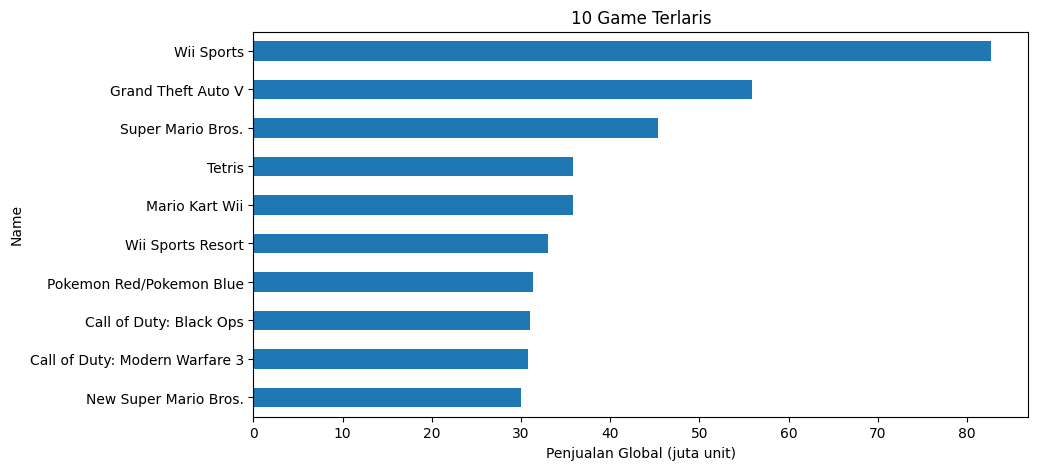

In [21]:
top_title = df.groupby('Name')['Global_Sales'].sum().nlargest(10)

top_title.sort_values().plot(kind='barh', figsize=(10,5))
plt.title('10 Game Terlaris')
plt.xlabel('Penjualan Global (juta unit)')
plt.show()

In [22]:
df['Publisher'] = df['Publisher'].replace('unknown', 'Unknown')

In [23]:
df.groupby('Genre')['Global_Sales'].sum().sort_values()

,Global_Sales
Genre,
Strategy,175.12
Adventure,239.04
Puzzle,244.95
Simulation,392.20
Fighting,448.91
Racing,732.04
Misc,809.96
Platform,831.37
Role-Playing,927.37


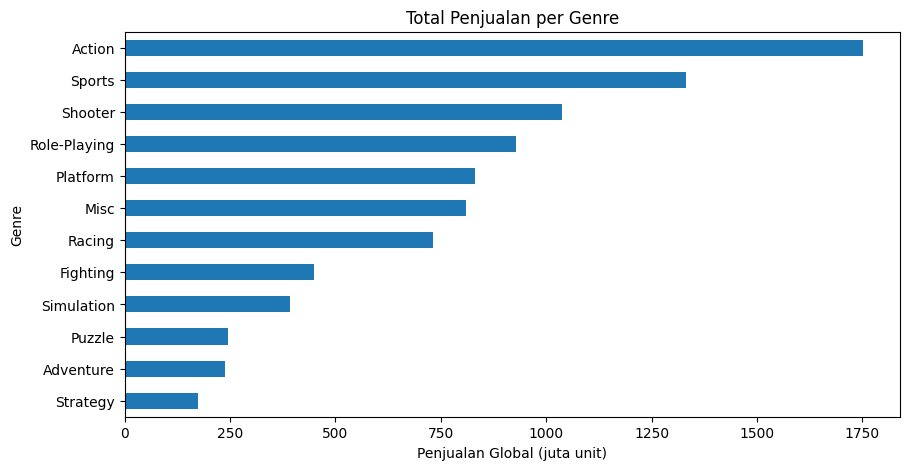

In [24]:
genre = df.groupby('Genre')['Global_Sales'].sum().sort_values()
genre.plot(kind='barh', figsize=(10,5), title='Total Penjualan per Genre')
plt.xlabel('Penjualan Global (juta unit)')
plt.show()

In [25]:
df.groupby('Genre')[['NA_Sales','EU_Sales','JP_Sales','Other_Sales']].sum()

,NA_Sales,EU_Sales,JP_Sales,Other_Sales
Genre,,,,
Action,877.83,525.00,159.95,187.38
Adventure,105.80,64.13,52.07,16.81
Fighting,223.59,101.32,87.35,36.68
Misc,410.24,215.98,107.76,75.32
Platform,447.05,201.63,130.77,51.59
Puzzle,123.78,50.78,57.31,12.55
Racing,359.42,238.39,56.69,77.27
Role-Playing,327.28,188.06,352.31,59.61
Shooter,582.60,313.27,38.28,102.69


NA_Sales             Action
EU_Sales             Action
JP_Sales       Role-Playing
Other_Sales          Action
dtype: object


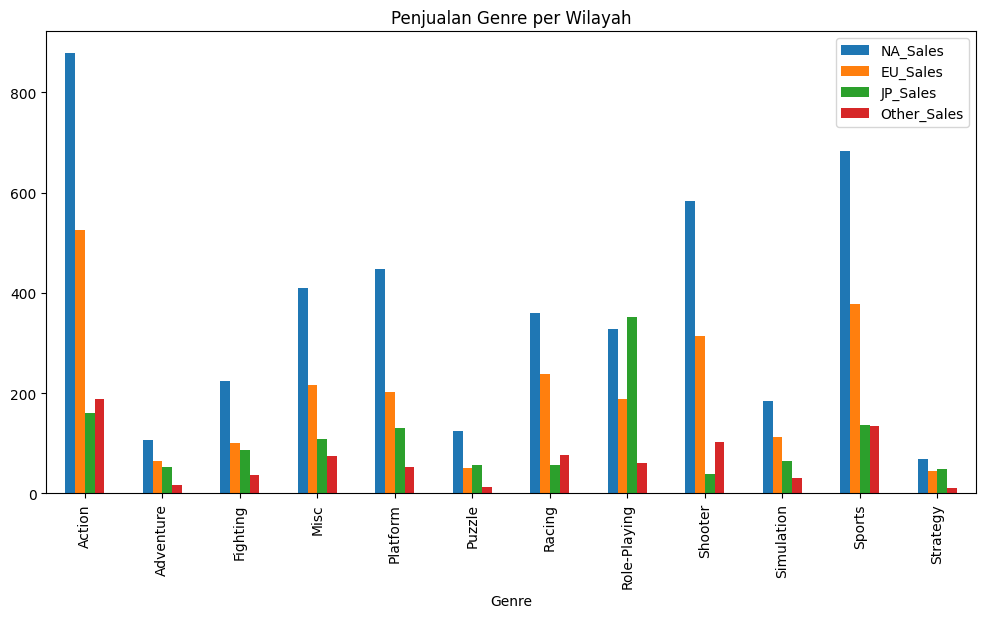

In [26]:
region = df.groupby('Genre')[['NA_Sales','EU_Sales','JP_Sales','Other_Sales']].sum()
print(region.idxmax())            # genre terlaris per wilayah

region.plot(kind='bar', figsize=(12,6), title='Penjualan Genre per Wilayah')
plt.show()